# FundusVision - Retinal vessel segmentation (U-Net)

A 4-level U-Net trained from scratch to label every pixel of a fundus photograph as **vessel** or
**background**. Masks are thin structures covering ~7% of the image, so IoU and Dice on the vessel
class are the metrics that matter; pixel accuracy is dominated by background.

```bash
fundusvision download vessel          # ~1.6 GB from Kaggle (needs ~/.kaggle/kaggle.json)
fundusvision train-segmentation       # writes results/segmentation/{best_model.pt,history.json}
fundusvision eval-segmentation        # writes results/segmentation/metrics.json + docs/figures/*.png
```

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)  # run-relative paths (results/, data/) resolve from the repo root
FIGURES = ROOT / "docs" / "figures"
pd.set_option("display.precision", 4)

DATA_DIR = ROOT / "data" / "vessel_segmentation"
RUN_DIR = ROOT / "results" / "segmentation"

## 1. Data

600 training pairs (split 80/20 into train/validation with a fixed seed) and 200 held-out test pairs,
resized to 224 x 224. Masks are binarised at `> 127`; nearest-neighbour resizing keeps them crisp.

600 training pairs at 224px


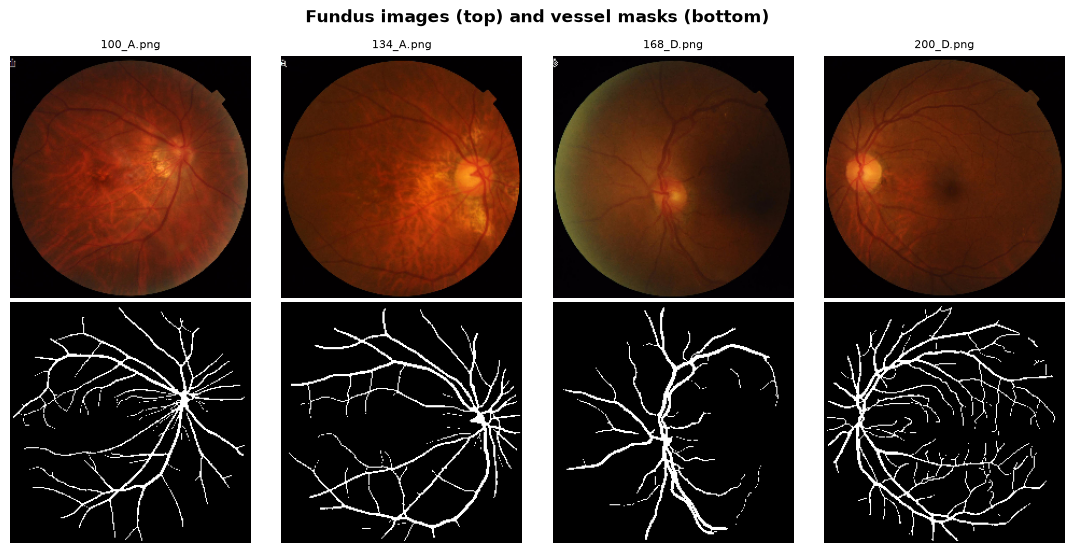

In [2]:
import matplotlib.pyplot as plt

from fundusvision.data.vessel import VesselSegmentationDataset, find_split_dir

train_ds = VesselSegmentationDataset(find_split_dir(DATA_DIR, "train"), cache=False)
print(f"{len(train_ds)} training pairs at {train_ds.image_size}px")
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for col in range(4):
    img, mask = train_ds.pair(col * 37)
    axes[0, col].imshow(img)
    axes[1, col].imshow(mask, cmap="gray")
    axes[0, col].set_title(train_ds.names[col * 37], fontsize=8)
    for r in range(2):
        axes[r, col].axis("off")
fig.suptitle("Fundus images (top) and vessel masks (bottom)", fontweight="bold")
plt.tight_layout()

## 2. Training

20 epochs of Adam at a constant 1e-4 with cross-entropy loss and no augmentation; the checkpoint
with the best validation Dice is kept (~15 min on an Apple-silicon GPU). Flip augmentation *hurts* on this
small set (−0.13 Dice) and cosine annealing is neutral; see the ablation in `docs/segmentation.md`.

In [3]:
RUN_TRAINING = False

if RUN_TRAINING:
    from fundusvision.training import SegmentationConfig, train_segmentation

    train_segmentation(SegmentationConfig(data_dir=DATA_DIR, output_dir=RUN_DIR))
else:
    print(f"Using the saved run in {RUN_DIR.relative_to(ROOT)}")

history = pd.DataFrame(pd.read_json(RUN_DIR / "history.json"))
history[["epoch", "train_loss", "val_loss", "val_pixel_accuracy", "val_iou", "val_dice", "best"]]

Using the saved run in results/segmentation


,epoch,train_loss,val_loss,val_pixel_accuracy,val_iou,val_dice,best
0,1,0.3666,0.2923,0.9387,0.2138,0.3523,True
1,2,0.2542,0.2645,0.9411,0.4029,0.5744,True
2,3,0.2118,0.1944,0.9572,0.5056,0.6716,True
3,4,0.1807,0.1734,0.9616,0.5597,0.7177,True
4,5,0.1572,0.1474,0.9657,0.5988,0.7491,True
5,6,0.1383,0.1339,0.9674,0.6326,0.7749,True
6,7,0.1237,0.1198,0.9702,0.6535,0.7905,True
7,8,0.1126,0.1109,0.9709,0.6555,0.7919,True
8,9,0.1037,0.1021,0.9725,0.6709,0.8030,True
9,10,0.0964,0.0965,0.9736,0.6879,0.8151,True


## 3. Test-set evaluation

In [4]:
from fundusvision.evaluation import evaluate_segmentation

report = evaluate_segmentation(RUN_DIR, data_dir=DATA_DIR, figures_dir=FIGURES)
pd.Series(report["test"]).to_frame("test").T

test: pixel acc 0.9753 | IoU 0.6932 | Dice 0.8188 | mean per-image Dice 0.8030 (200 images)


,pixel_accuracy,iou,dice,precision,recall,mean_image_dice,images
test,0.9753,0.6932,0.8188,0.8581,0.783,0.803,200.0


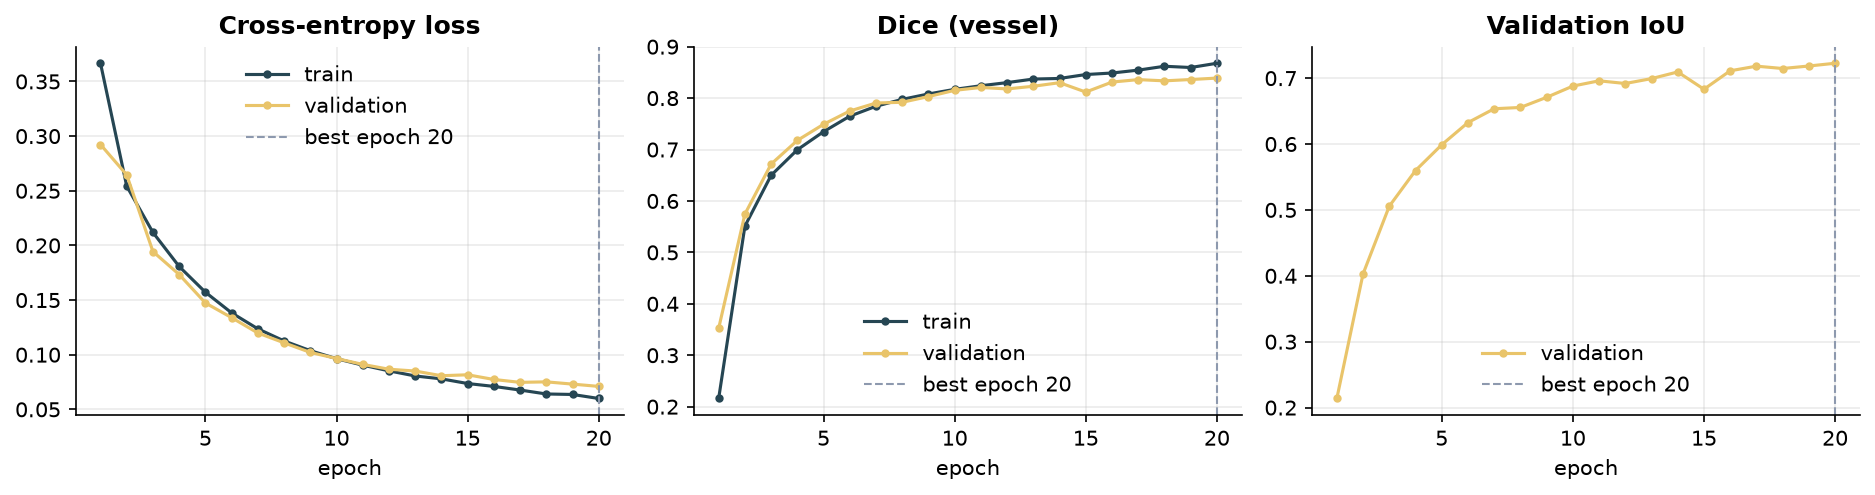

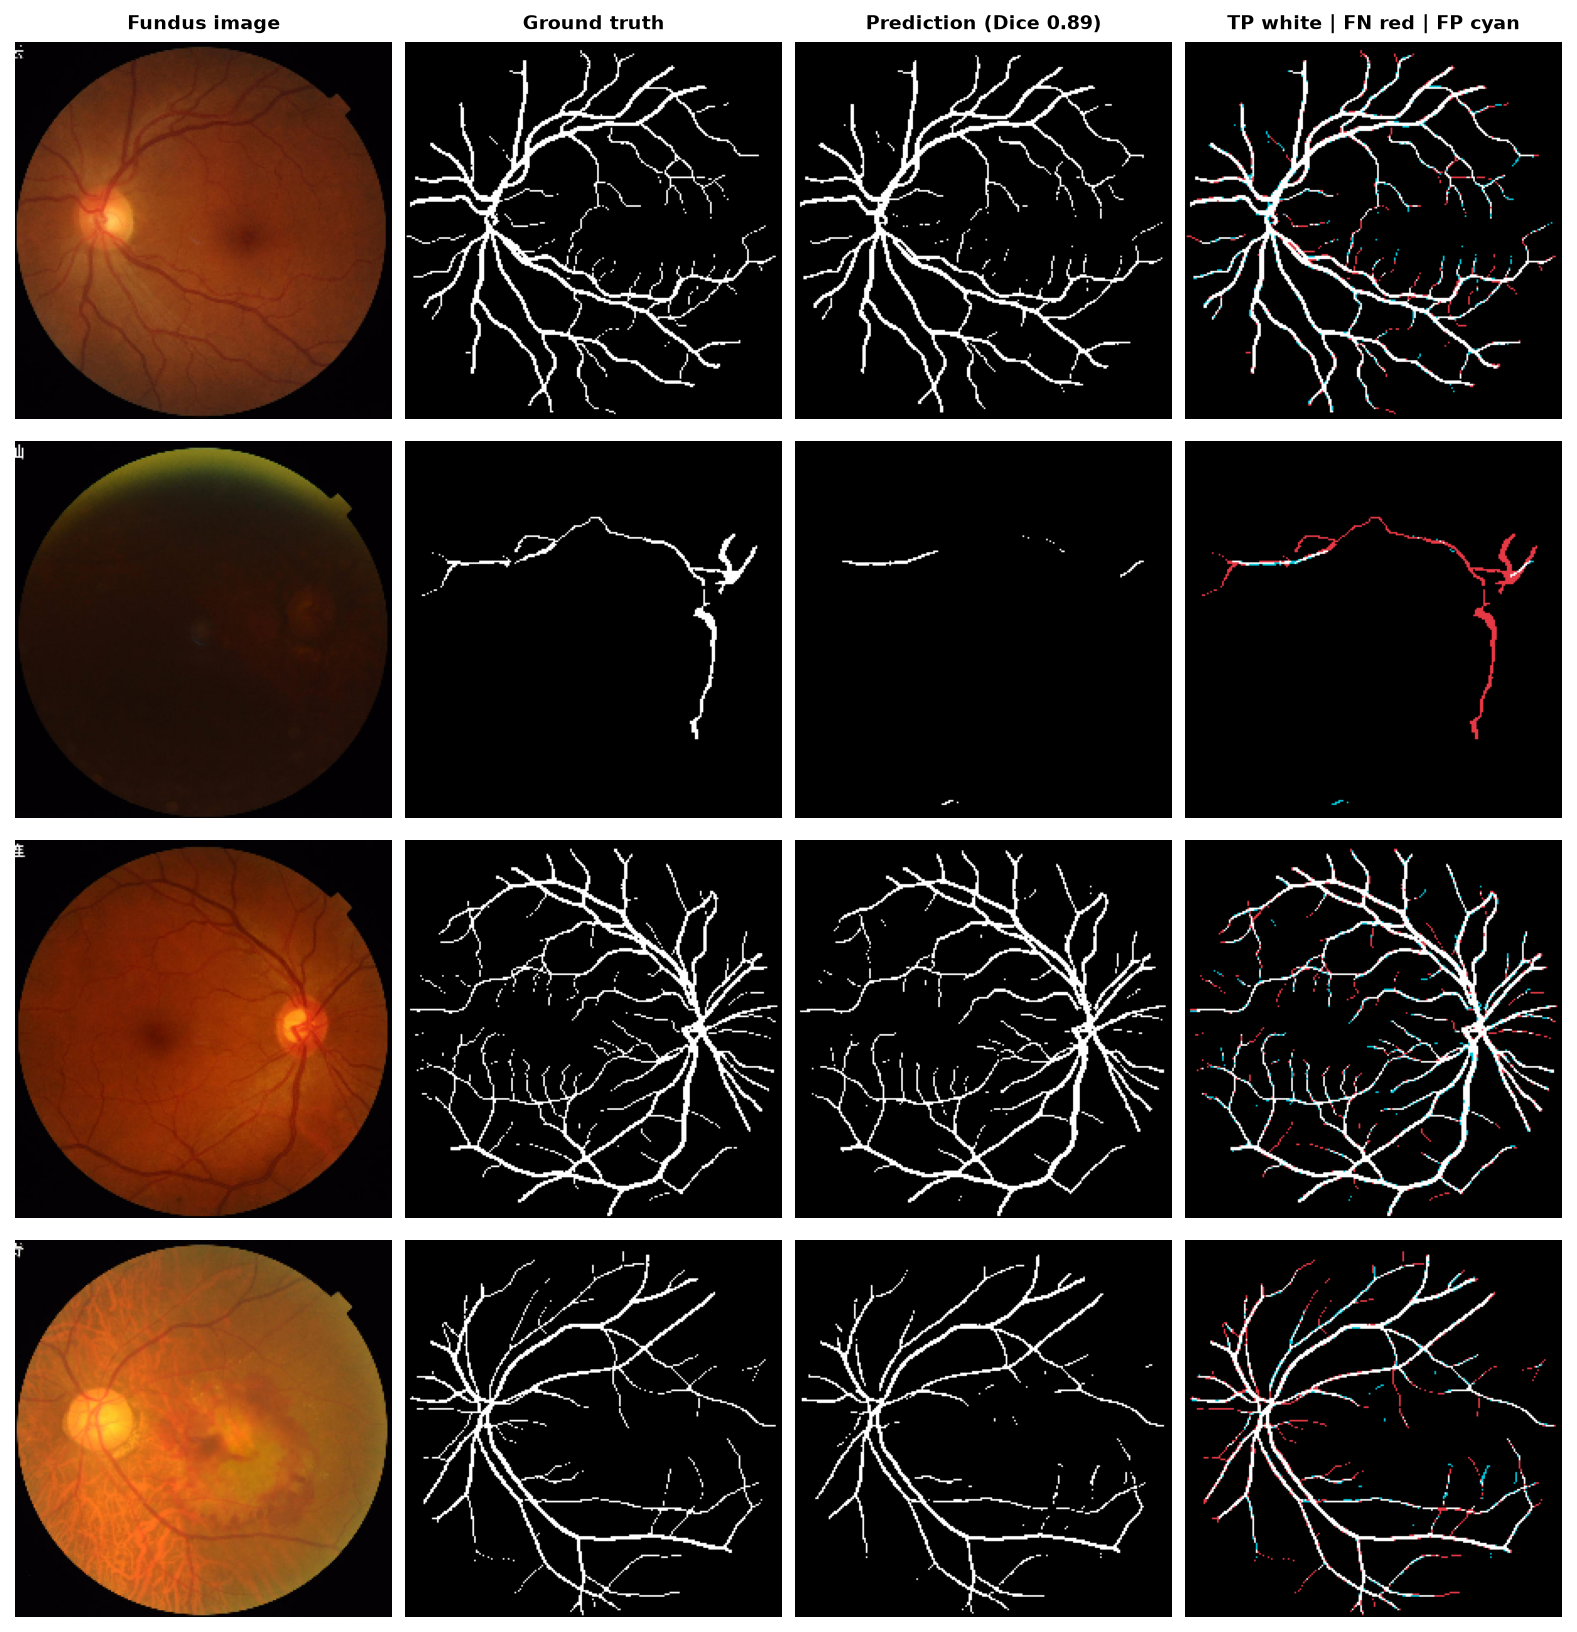

In [5]:
display(Image(filename=FIGURES / "segmentation_training_curves.png"))
display(Image(filename=FIGURES / "segmentation_examples.png"))

## Notes

* The overlay panels colour true positives white, missed vessel pixels red and spurious predictions
  cyan: errors concentrate on the thinnest capillaries and at the optic disc rim.
* Improvements worth trying: a Dice or Tversky loss term, elastic/rotation augmentation, higher input
  resolution (vessels are 1-3 px wide at 224 px), and attention gates on the skip connections.